<a href="https://colab.research.google.com/github/BajaniyaDEV/passscore/blob/Dev/notebooks/01_bigram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PassScore – Notebook 1: Bigram models

PassScore trains a character-level language model on common passwords. The model learns what typical passwords look like, so it can score any new password: the more "normal" a password looks to the model, the more predictable (and weaker) it is.

The score is the password's surprise in bits: the sum of `-log2 p(next character)` over every character plus the end token.

This notebook follows **makemore part 1** (video 1):
- **Part 1:** bigram model by counting pairs of characters
- **Part 1b:** the same bigram model as a neural network, trained with gradient descent

Cells are labelled `part.cell` (1.03 is part 1, cell 3) and each code cell starts with a comment saying what it does.

**Author:** Bajaniya Dev

## Part 0: setup and data

Loads the xato-net password list, cleans it and builds the character vocabulary. Same first steps as every makemore notebook, with passwords instead of names.

In [2]:
# ---- Cell 0.02: Load and clean the password list ----
# Downloads the xato-net list of 1,000,000 common passwords from SecLists on GitHub.
# Keeps passwords that are 4-30 characters long and only use the 94 printable keyboard characters
# (letters, digits, punctuation). makemore part 1 equivalent: words = open('names.txt')...
import torch, urllib.request, string, secrets, math, random
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/danielmiessler/SecLists/master/Passwords/Common-Credentials/xato-net-10-million-passwords-1000000.txt"
raw = urllib.request.urlopen(url).read().decode("utf-8", errors="ignore").splitlines()

chars = sorted(set(string.ascii_letters + string.digits + string.punctuation))  # 94 chars
allowed = set(chars)
words = [w for w in raw if 4 <= len(w) <= 30 and all(c in allowed for c in w)]

print(len(raw), "raw ->", len(words), "kept")
print(words[:15])

1000000 raw -> 999154 kept
['123456', 'password', '12345678', 'qwerty', '123456789', '12345', '1234', '111111', '1234567', 'dragon', '123123', 'baseball', 'abc123', 'football', 'monkey']


In [3]:
# ---- Cell 0.03: Vocabulary and first train/test split ----
# stoi/itos map each character to an integer and back. Index 0 ('\n') is the start/end token,
# doing the job of '.' in makemore (here '.' is a real password character, so it can't be used).
# V = 95 (94 characters + the token). Shuffles with seed 42 and splits 90% train / 10% test for the bigram model.
stoi = {c: i + 1 for i, c in enumerate(chars)}
stoi["\n"] = 0
itos = {i: c for c, i in stoi.items()}
V = len(stoi)   # 95

random.seed(42)
random.shuffle(words)
n = int(0.9 * len(words))
train, test = words[:n], words[n:]
print("vocab:", V, "| train:", len(train), "| test:", len(test))

vocab: 95 | train: 899238 | test: 99916


## Part 1: bigram model (makemore part 1)

Predicts each character from the one before it by counting pairs. Gives the first strength score and a baseline loss for the MLP to beat.

In [4]:
# ---- Cell 1.01: Count bigrams and build the probability matrix ----
# pairs() wraps each password in start/end tokens and returns (current char, next char) index pairs.
# bincount counts all pairs at once into the V x V matrix N (makemore's N[ix1, ix2] += 1 loop, but fast).
# +1 smoothing so no pair has zero probability, then each row is normalised so it sums to 1.
def pairs(ws):
    ix1, ix2 = [], []
    for w in ws:
        seq = [0] + [stoi[c] for c in w] + [0]
        ix1 += seq[:-1]
        ix2 += seq[1:]
    return torch.tensor(ix1), torch.tensor(ix2)

a, b = pairs(train)
N = torch.bincount(a * V + b, minlength=V * V).view(V, V)

P = (N + 1).float()               # +1 smoothing so nothing has zero probability
P /= P.sum(1, keepdim=True)

In [5]:
# ---- Cell 1.02: Test loss vs a uniform guess ----
# Average negative log likelihood of the real next characters in the test set.
# A uniform guess over 95 characters scores log(95) = 4.55; the bigram model gets about 3.06.
ta, tb = pairs(test)
test_nll = -torch.log(P[ta, tb]).mean().item()
print(f"uniform guess loss: {math.log(V):.3f}")
print(f"bigram test loss:   {test_nll:.3f}")

uniform guess loss: 4.554
bigram test loss:   3.061


In [6]:
# ---- Cell 1.03: Password strength score in bits (bigram) ----
# strength_bits adds up -log P(next char | current char) over the whole password, including the end token,
# and divides by log(2) to convert nats to bits. Predictable passwords get low scores.
# random_pw makes truly random passwords with secrets, which should score high.
# The tests list defined here is reused in cell 3.03 to compare against the MLP.
def strength_bits(pw):
    seq = [0] + [stoi[c] for c in pw if c in stoi] + [0]
    nll = -sum(math.log(P[x, y].item()) for x, y in zip(seq, seq[1:]))
    return nll / math.log(2)

def random_pw(k=12):
    return "".join(secrets.choice(chars) for _ in range(k))

tests = ["password", "password123", "iloveyou", "qwerty2024",
         "Tr0ub4dor&3", "correcthorsebatterystaple", random_pw(), random_pw()]
for pw in tests:
    print(f"{pw:28s} {strength_bits(pw):6.1f} bits")

password                       37.4 bits
password123                    46.9 bits
iloveyou                       39.2 bits
qwerty2024                     44.2 bits
Tr0ub4dor&3                    82.2 bits
correcthorsebatterystaple     107.1 bits
[fqNOL1b[kC0                  110.9 bits
;bGj&+,jKfwH                  115.3 bits


In [7]:
# ---- Cell 1.04: Generate fake passwords (bigram) ----
# Starts at the start token, samples the next character from that row of P, and stops at the end token.
# Same sampling loop as makemore part 1. The output looks password-ish but has no memory beyond one character.
g = torch.Generator().manual_seed(2147483647)
for _ in range(15):
    out, ix = [], 0
    while True:
        ix = torch.multinomial(P[ix], 1, generator=g).item()
        if ix == 0:
            break
        out.append(itos[ix])
    print("".join(out))

s119
zeillaxxBiand
1007wan
30kaquchur6
ae
JAartet6
14f3544
vveror5
xho5569945
gthgmugic
luekt531
10090677aas
x43
ahamer19281
guog3df


## Part 1b: bigram as a neural network (makemore part 1, second half)

Same bigram model, but instead of counting, a 95×95 weight matrix W is learned by gradient descent. If it works, its loss should end up close to the counting model's.

In [8]:
# ---- Cell 1.05: Bigram neural net - setup ----
# Reuses a (current char) and b (next char) from cell 1.01 as inputs xs and targets ys.
# W is the network's only weight matrix: 95 x 95, random at the start.
# requires_grad=True tells PyTorch to track W so it can compute gradients for it.
import torch.nn.functional as F

xs, ys = a, b
num = xs.nelement()
print("training pairs:", num)

g = torch.Generator().manual_seed(2147483647)
W = torch.randn((V, V), generator=g, requires_grad=True)

training pairs: 7698803


step     0: loss 5.0930
step   500: loss 3.1537
step  1000: loss 3.1239
step  1500: loss 3.0648
step  2000: loss 3.0790
step  2500: loss 3.1238


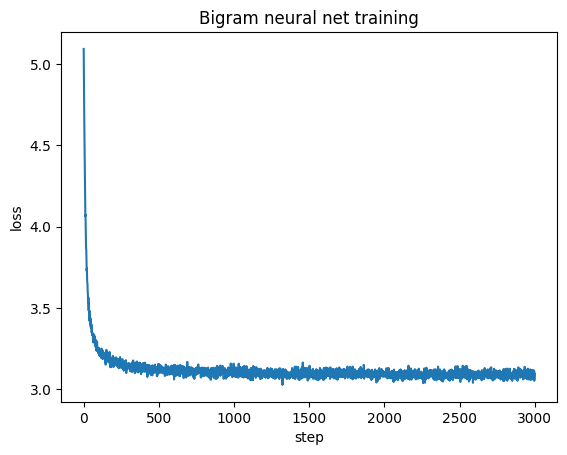

In [9]:
# ---- Cell 1.06: Bigram neural net - training loop ----
# Minibatches: there are ~7.5 million pairs, and one-hot encoding all of them at once
# (7.5M x 95 numbers) would need about 2.8 GB of memory, so each step uses a random batch of 4096.
# Each step: one-hot -> logits -> softmax -> loss -> backward -> update (makemore part 1).
batch_size = 4096
lossi_bigram = []

for k in range(3000):
    # pick a random batch of pairs
    ix = torch.randint(0, num, (batch_size,), generator=g)

    # forward pass
    xenc = F.one_hot(xs[ix], num_classes=V).float()   # each char -> 95 zeros with one 1
    logits = xenc @ W                                 # picks the row of W for each char
    counts = logits.exp()                             # softmax, part 1: make everything positive
    probs = counts / counts.sum(1, keepdim=True)      # softmax, part 2: each row sums to 1
    loss = -probs[torch.arange(batch_size), ys[ix]].log().mean() + 0.01 * (W**2).mean()

    # backward pass
    W.grad = None
    loss.backward()

    # update (big steps first, smaller steps at the end)
    lr = 50 if k < 2000 else 10
    W.data += -lr * W.grad

    lossi_bigram.append(loss.item())
    if k % 500 == 0:
        print(f"step {k:5d}: loss {loss.item():.4f}")

plt.plot(lossi_bigram)
plt.xlabel("step"); plt.ylabel("loss"); plt.title("Bigram neural net training")
plt.show()

In [10]:
# ---- Cell 1.07: Bigram neural net - test loss and samples ----
# W[ta] gives exactly the same result as one_hot(ta) @ W, but uses far less memory.
# F.cross_entropy does softmax + negative log likelihood in one step (the same math as above).
with torch.no_grad():
    test_loss_nn = F.cross_entropy(W[ta], tb).item()

print(f"uniform guess:          {math.log(V):.3f}")
print(f"bigram (counting):      {test_nll:.3f}")
print(f"bigram (neural net):    {test_loss_nn:.3f}")

# generate passwords from the neural net
g2 = torch.Generator().manual_seed(2147483647)
for _ in range(10):
    out, ix = [], 0
    while True:
        with torch.no_grad():
            p = F.softmax(W[ix], dim=0)
        ix = torch.multinomial(p, 1, generator=g2).item()
        if ix == 0:
            break
        out.append(itos[ix])
    print("".join(out))

uniform guess:          4.554
bigram (counting):      3.061
bigram (neural net):    3.073
s119
zeillaxxBiand
1007wan
30kaq>%hur6
ae
JAartete
14f3544
vveror5
xholkil945
g)hgmugic
